In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import box

def generate_grid_perfect_alignment(tif_path, output_csv="grid_portugal_1km.csv"):
    print("Alignement de la grille sur les pixels du Landcover")
    
    with rasterio.open(tif_path) as src:
        nodata_value = src.nodata
        raster_crs = src.crs
        
      
        bbox_gdf = gpd.GeoDataFrame(
            geometry=[box(*src.bounds)], crs=src.crs
        ).to_crs("EPSG:3763")
        minx, miny, maxx, maxy = bbox_gdf.total_bounds
        
       
        spacing = 1000 
        xs = np.arange(minx, maxx + spacing, spacing)
        ys = np.arange(miny, maxy + spacing, spacing)
        xx, yy = np.meshgrid(xs, ys)
        coords_metric = np.column_stack([xx.ravel(), yy.ravel()])
        
        
        grid_gdf = gpd.GeoDataFrame(
            geometry=gpd.points_from_xy(coords_metric[:, 0], coords_metric[:, 1]),
            crs="EPSG:3763"
        )
        
       
        grid_raster_crs = grid_gdf.to_crs(raster_crs)
        raster_coords = [(geom.x, geom.y) for geom in grid_raster_crs.geometry]
        
        print("Filtrage par pixel")
        
        sampled_values = [v[0] for v in src.sample(raster_coords)]
        grid_gdf['landcover'] = sampled_values

       
        grid_gdf = grid_gdf[grid_gdf['landcover'] != nodata_value]
        grid_gdf = grid_gdf[grid_gdf['landcover'] > 0] 
       
        grid_final = grid_gdf.to_crs("EPSG:4326")
        df_final = pd.DataFrame({
            'latitude': grid_final.geometry.y,
            'longitude': grid_final.geometry.x,
            'landcover': grid_final['landcover']
        })

    df_final.to_csv(output_csv, index=False)
    print(f"Terminé : {len(df_final):,} points parfaitement alignés sur le raster.")
    return df_final

df_portugal = generate_grid_perfect_alignment(r"\..\..\Data\Land_Cover\landcover_portugal_300m.tif")

🎨 Préparation de la carte...
ℹ️ Aucun shapefile fourni, utilisation de l'emprise des points.


C:\Users\admin\AppData\Local\Temp\ipykernel_21736\720507944.py:23: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  portugal_map = grid_gdf.convex_hull.buffer(0.1)


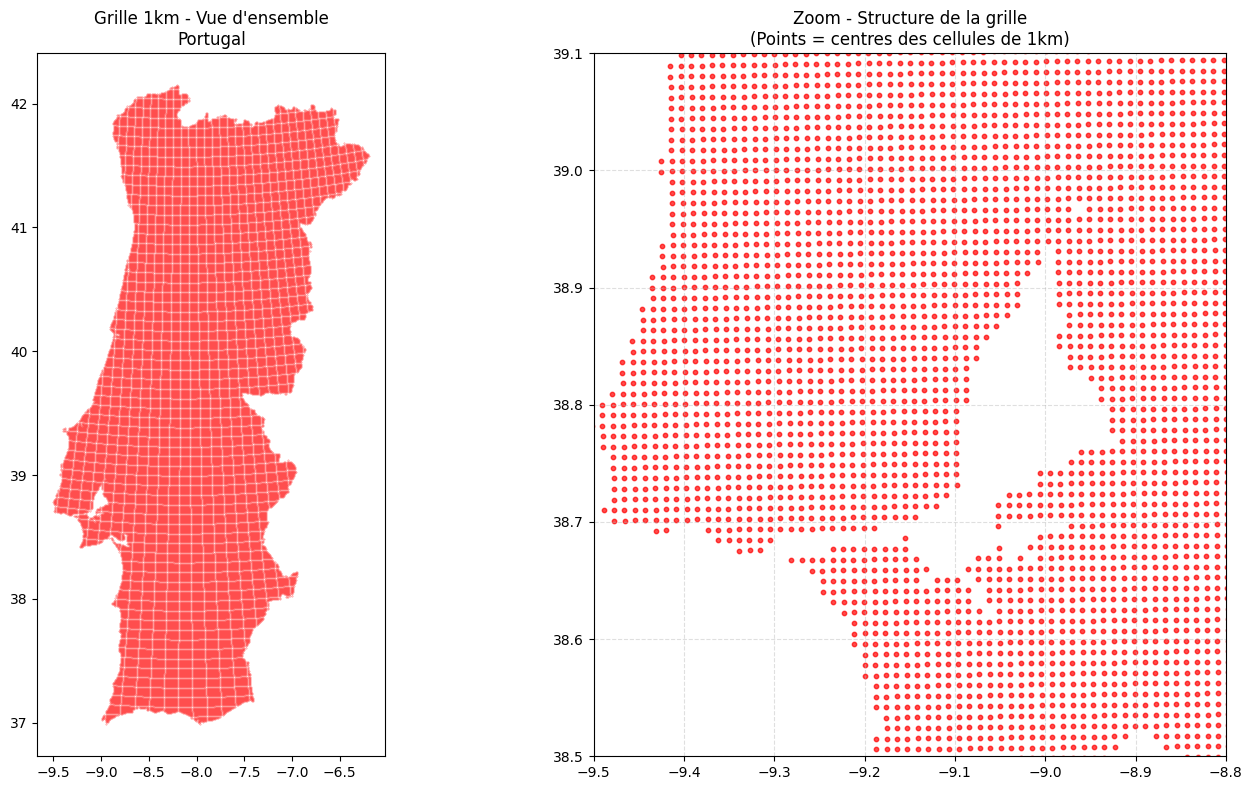

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd

def visualiser_grille_portugal(points_csv, background_shp=None):
  
    print("🎨 Préparation de la carte...")
    
 
    df = pd.read_csv(points_csv)
    grid_gdf = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326"
    )

   
    if background_shp:
        portugal_map = gpd.read_file(background_shp).to_crs("EPSG:4326")
    else:
      
        print("Aucun shapefile fourni, utilisation de l'emprise des points.")
        portugal_map = grid_gdf.convex_hull.buffer(0.1) 

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))
    
   
    if background_shp:
        portugal_map.plot(ax=ax1, color='lightgrey', edgecolor='black', alpha=0.5)
    
   
    grid_gdf.plot(ax=ax1, color='red', markersize=0.1, alpha=0.5)
    ax1.set_title("Grille 1km - Vue d'ensemble\nPortugal")
    
   
    zoom_bounds = [-9.5, 38.5, -8.8, 39.1] 
    ax2.set_xlim(zoom_bounds[0], zoom_bounds[2])
    ax2.set_ylim(zoom_bounds[1], zoom_bounds[3])
    
    if background_shp:
        portugal_map.plot(ax=ax2, color='lightgreen', edgecolor='black')
    
   
    grid_gdf.plot(ax=ax2, color='red', markersize=10, alpha=0.7)
    
   
    ax2.grid(True, linestyle='--', alpha=0.4)
    ax2.set_title("Zoom - Structure de la grille\n(Points = centres des cellules de 1km)")
    
    plt.tight_layout()
    plt.show()


visualiser_grille_portugal(
    points_csv="grid_portugal_1km.csv",
)